In [7]:
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt 
import sys
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.utils import load_biomass_data, merge_3d_arrays_with_mean, crop_to_non_nan, split_into_quadrants, merge_3d_arrays_with_max
import numpy as np

In [2]:

# Example usage
parent_path = '/home/grace.bcolverd/'
band_opt = 'P'
heading = 'NW'
acquisition_mode = 'monostatic'
polarimetric_channel = 'HV'
# above_ground_elevation = 20

data = load_biomass_data(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel)

# Access the returned objects
IncAngleUTM = data['IncAngleUTM']
easting_axis = data['easting_axis']
northing_axis = data['northing_axis']
LidarCHM = data['LidarCHM']
PcubeNormUTM = data['PcubeNormUTM']
z_axis = data['z_axis']
PcubeDeRampedUTM = data['PcubeDeRampedUTM']
head_ind = data['head_ind']
mono_bi_ind = data['mono_bi_ind']
pol_ind = data['pol_ind']


Starting to load the biomass data
Load complete


In [6]:
# merge headings togethers  - defines in and tested in utils 
df = PcubeDeRampedUTM

head1 = df[:, :, :, :, 0]
head2 = df[:, :, :, :, 1]

m = merge_3d_arrays_with_max(head1, head2 )

In [3]:
import numpy as np
import matplotlib.pyplot as plt


# def split_into_quadrants(array3d, array2d ):
#     print(array3d.shape[1] , array2d.shape[1])
#     if array3d.shape[0] != array2d.shape[0] or array3d.shape[1] != array2d.shape[1]:
#         raise ValueError('shape mismathc between two arrays')

#     x_mid = array3d.shape[0] // 2
#     y_mid = array3d.shape[1] // 2

#     # Define the quadrants
#     q1 = array3d[:x_mid, :y_mid, :]
#     q2 = array3d[:x_mid, y_mid:, :]
#     q3 = array3d[x_mid:, :y_mid, :]
#     q4 = array3d[x_mid:, y_mid:, :]

#     gt1 = array2d[:x_mid, :y_mid]
#     gt2 = array2d[:x_mid, y_mid:]
#     gt3 = array2d[x_mid:, :y_mid]
#     gt4 = array2d[x_mid:, y_mid:]
#     return (q1,q2,q3,q4) , (gt1, gt2, gt3, gt4 )


In [ ]:

# # Example usage
# parent_path = '/home/grace.bcolverd/'
# band_opt = 'P'
# heading = 'NW'
# acquisition_mode = 'monostatic'
# polarimetric_channel = 'HV'
# # above_ground_elevation = 20

# data = load_biomass_data(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel)

# # Access the returned objects
# IncAngleUTM = data['IncAngleUTM']
# easting_axis = data['easting_axis']
# northing_axis = data['northing_axis']
# LidarCHM = data['LidarCHM']
# PcubeNormUTM = data['PcubeNormUTM']
# z_axis = data['z_axis']
# PcubeDeRampedUTM = data['PcubeDeRampedUTM']
# head_ind = data['head_ind']
# mono_bi_ind = data['mono_bi_ind']
# pol_ind = data['pol_ind']


In [3]:

from torch.utils.data import Dataset, DataLoader
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset


def merge_headings(df):
    
    head1 = df[:, :, :, :, 0]
    head2 = df[:, :, :, :, 1]

    return merge_3d_arrays_with_max(head1, head2 )

def generate_quadrants(parent_path, polarimetric_channel ):

    acquisition_mode = 'monostatic'
    band_opt = 'P'
    heading = 'NW'
    data = load_biomass_data(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel)
      
    # load vals, option here for L band
    # PcubeNormUTM = data['PcubeNormUTM']
    LidarCHM = data['LidarCHM']
    PcubeDeRampedUTM = data['PcubeDeRampedUTM']
    pol_ind = data['pol_ind']

    merged_power_cube = merge_headings(PcubeDeRampedUTM)
    intensity_cube = merged_power_cube[:,:,:,pol_ind]
    
    # Crop LidarCHM
    cropped_LidarCHM = crop_to_non_nan(LidarCHM)

    print(f"Original shape: {LidarCHM.shape}")
    print(f"Cropped shape: {cropped_LidarCHM.shape}")

    # If you need to crop other arrays to the same dimensions:
    row_start = np.argmax(~np.all(np.isnan(LidarCHM), axis=1))
    row_end = len(LidarCHM) - np.argmax(~np.all(np.isnan(LidarCHM), axis=1)[::-1])
    col_start = np.argmax(~np.all(np.isnan(LidarCHM), axis=0))
    col_end = len(LidarCHM[0]) - np.argmax(~np.all(np.isnan(LidarCHM), axis=0)[::-1])

    # Crop Intensity
    crop_int = intensity_cube[row_start:row_end, col_start:col_end, : ]

    # Split the array
    quadrants, ground_truths = split_into_quadrants(crop_int , cropped_LidarCHM)
    return quadrants, ground_truths


def generate_dataloaders(quadrants, ground_truths, patch_size, stride, test_quadrant=3, batch_size=4):
    quad_options = [0, 1, 2, 3]
    if test_quadrant not in quad_options:
        raise ValueError('Choose index 0-3 for test')
    
    # Remove test_quadrant from options
    remaining_quadrants = [x for x in quad_options if x != test_quadrant]
    
    # Assign train and val quadrants
    train_quadrants = remaining_quadrants[:2]  # Use first two remaining quadrants for training
    val_quadrant = remaining_quadrants[2]  # Use the last remaining quadrant for validation
    
    dataset = QuadrantPatchDataset(
        quadrants, ground_truths, 
        train_quadrants=train_quadrants, 
        test_quadrant=test_quadrant, 
        val_quadrant=val_quadrant, 
        patch_size=patch_size, 
        stride=stride
    )

    # Create DataLoaders
    dataset.set_mode('train')
    train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    dataset.set_mode('test')
    test_loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    
    dataset.set_mode('val')
    val_loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    return train_loader, test_loader, val_loader, dataset




In [8]:
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset 
from src.fdlbiomass.utils import split_into_quadrants
# Load data 
# Set variables 
parent_path = '/home/grace.bcolverd/'
polarimetric_channel = 'HH'
test_quadrant = 3

num_epochs = 50
lr =  0.001
batch_size = 4 
patch_size = (64, 64, 36)
stride = (32,32,36)
quadrants, ground_truths = generate_quadrants(parent_path, polarimetric_channel)
train_loader, test_loader, val_loader, dataset= generate_dataloaders(quadrants, ground_truths, patch_size, stride, test_quadrant=test_quadrant, batch_size=batch_size)


Starting to load the biomass data
Load complete
Original shape: (326, 840)
Cropped shape: (321, 665)
665 665


In [14]:
import numpy as np

def check_for_nan(data, name):
    if np.isnan(data).any() or np.isinf(data).any():
        print(f"Warning: {name} contains NaN or inf values")

check_for_nan(quadrants[0], "Input data")
check_for_nan(ground_truths[0], "Ground truth")

In [11]:
np.isnan(quadrants).sum()

1146960

In [15]:
quadrants[0].shape

(163, 420, 36)

In [ ]:
parent_path = '/home/grace.bcolverd/'
polarimetric_channel = 'HH'

patch_size = (64, 64, 36)
stride = (32,32,36)
test_quadrant = 3
quadrants, ground_truths = generate_quadrants(parent_path, polarimetric_channel)
train_loader, test_loader, val_loader, dataset= generate_dataloaders(quadrants, ground_truths, patch_size, stride, test_quadrant=3, batch_size=4)

840 840


In [19]:
import numpy as np




Original shape: (326, 840)
Cropped shape: (321, 665)


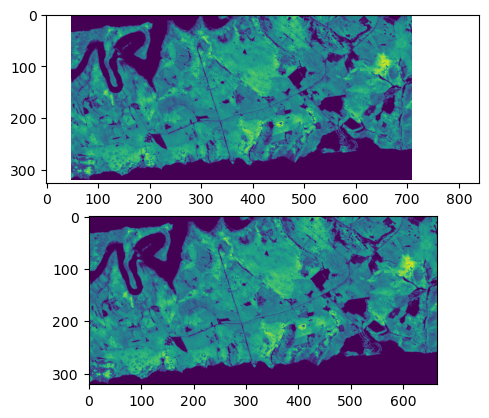

In [29]:
f, ax = plt.subplots(nrows=2) 
ax=ax.ravel() 
ax[0].imshow(LidarCHM)
ax[1].imshow(cropped_LidarCHM)


In [27]:

# cropped_other_array = other_array[row_start:row_end, col_start:col_end]

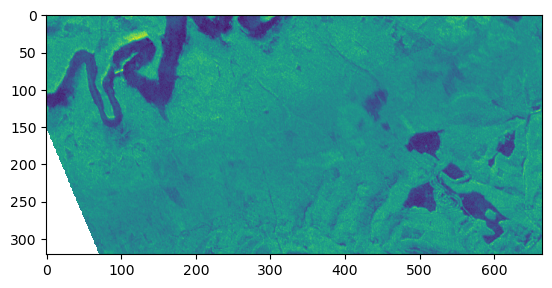

In [40]:
plt.imshow(crop_int[:,:,1])

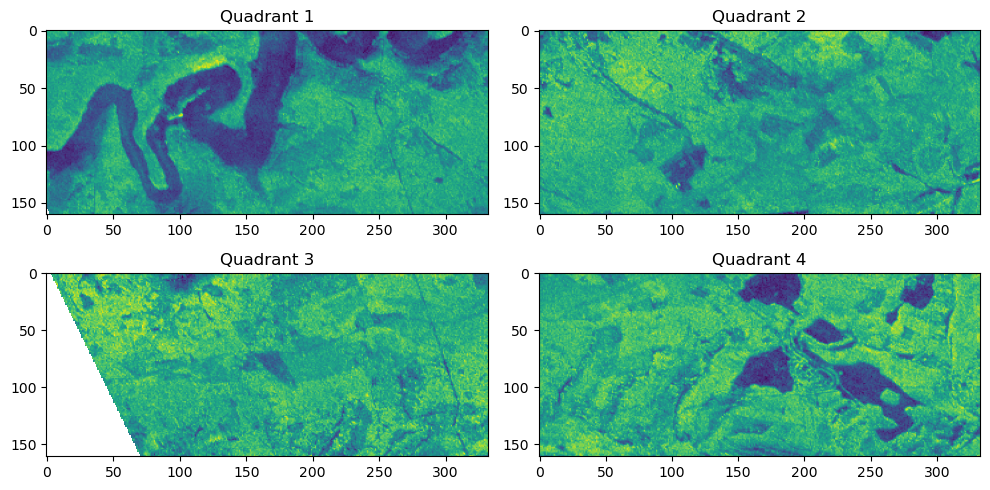

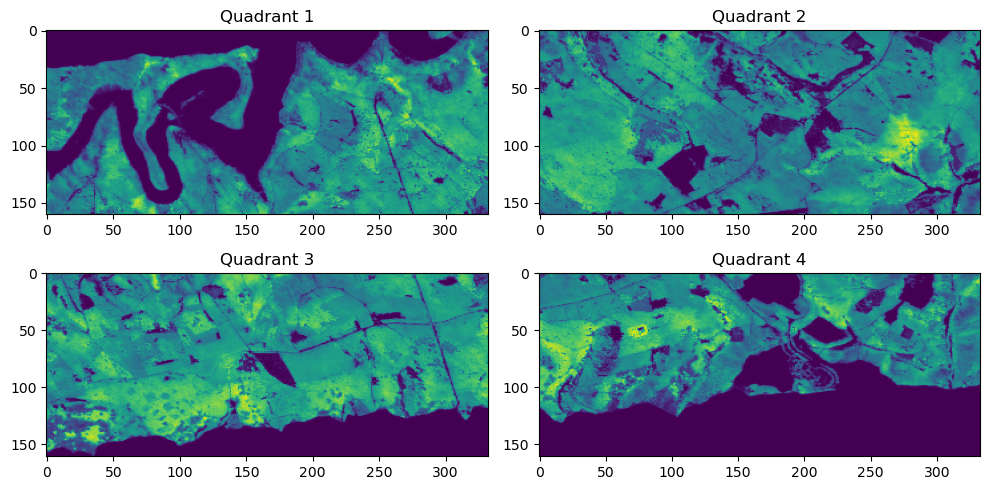

In [12]:

# Select a 2D slice along the z-axis (e.g., z=0)
z_index = 15
q1_slice = quadrants[0][:, :, z_index]
q2_slice = quadrants[1][:, :, z_index]
q3_slice = quadrants[2][:, :, z_index]
q4_slice = quadrants[3][:, :, z_index]

# Plot the quadrants
fig, axs = plt.subplots(2, 2, figsize=(10, 5))

axs[0, 0].imshow(q1_slice, cmap='viridis', aspect='auto')
axs[0, 0].set_title('Quadrant 1')
axs[0, 1].imshow(q2_slice, cmap='viridis', aspect='auto')
axs[0, 1].set_title('Quadrant 2')
axs[1, 0].imshow(q3_slice, cmap='viridis', aspect='auto')
axs[1, 0].set_title('Quadrant 3')
axs[1, 1].imshow(q4_slice, cmap='viridis', aspect='auto')
axs[1, 1].set_title('Quadrant 4')
plt.tight_layout()
# Plot the quadrants
fig, axs = plt.subplots(2, 2, figsize=(10,5))

axs[0, 0].imshow(ground_truths[0], cmap='viridis', aspect='auto')
axs[0, 0].set_title('Quadrant 1')
axs[0, 1].imshow(ground_truths[1], cmap='viridis', aspect='auto')
axs[0, 1].set_title('Quadrant 2')
axs[1, 0].imshow(ground_truths[2],  cmap='viridis', aspect='auto')
axs[1, 0].set_title('Quadrant 3')
axs[1, 1].imshow(ground_truths[3], cmap='viridis', aspect='auto')
axs[1, 1].set_title('Quadrant 4')
plt.tight_layout() 


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim



class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

class UNet3D(nn.Module):
    def __init__(self, in_channels, out_channels=1):
        super(UNet3D, self).__init__()

        self.encoder1 = DoubleConv(in_channels, 64)
        self.pool1 = nn.MaxPool3d(kernel_size=(2, 2, 1), stride=(2, 2, 1))
        self.encoder2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2))
        self.encoder3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool3d(kernel_size=(2, 2, 1), stride=(2, 2, 1))
        
        self.bottleneck = DoubleConv(256, 512)
        
        self.upconv3 = nn.ConvTranspose3d(512, 256, kernel_size=(2, 2, 1), stride=(2, 2, 1))
        self.decoder3 = DoubleConv(512, 256)
        self.upconv2 = nn.ConvTranspose3d(256, 128, kernel_size=(2, 2, 2), stride=(2, 2, 2))
        self.decoder2 = DoubleConv(256, 128)
        self.upconv1 = nn.ConvTranspose3d(128, 64, kernel_size=(2, 2, 1), stride=(2, 2, 1))
        self.decoder1 = DoubleConv(128, 64)

        # reduce the 36 dims 
        self.final_conv = nn.Conv3d(64, out_channels, kernel_size=(1, 1, 36))
        self.final_activation = nn.ReLU()

        # Change this to a 3D convolution that reduces the depth to 1
        self.final_conv = nn.Conv3d(64, out_channels, kernel_size=(1, 1, 36))
        self.final_activation = nn.ReLU()

    def forward(self, x):
        enc1 = self.encoder1(x)
        enc2 = self.encoder2(self.pool1(enc1))
        enc3 = self.encoder3(self.pool2(enc2))

        bottleneck = self.bottleneck(self.pool3(enc3))

        dec3 = self.upconv3(bottleneck)
        dec3 = torch.cat((dec3, enc3), dim=1)
        dec3 = self.decoder3(dec3)
        dec2 = self.upconv2(dec3)
        dec2 = torch.cat((dec2, enc2), dim=1)
        dec2 = self.decoder2(dec2)
        dec1 = self.upconv1(dec2)
        dec1 = torch.cat((dec1, enc1), dim=1)
        dec1 = self.decoder1(dec1)
        
        output = self.final_conv(dec1)
        output = self.final_activation(output)
        print('op shape ' , output.shape)
        output = torch.squeeze(output)  # Remove the depth dimension
        print('sq sh', output.shape)
        return output

    def __str__(self):
        return f"{self.__class__.__name__}"

In [7]:


# from torch.utils.data import Dataset, DataLoader
# from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset

# dataset = QuadrantPatchDataset(quadrants, ground_truths, train_quadrants=[0, 1], test_quadrant=2, val_quadrant=3, patch_size=64, stride=32)


# dataset = QuadrantPatchDataset(
#     quadrants, ground_truths, 
#     train_quadrants=[0, 1], test_quadrant=2, val_quadrant=3, 
#     patch_size=(64, 64, 36), stride=(16, 16, 36)
# )

# # Create DataLoaders
# batch_size = 4 
# train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
# dataset.set_mode('test')
# test_loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
# dataset.set_mode('val')
# val_loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

# # Example of iterating through the data
# dataset.set_mode('train')
# for intensity_patch, ground_truth_patch in train_loader:
#     # Your training loop here
#     print(f"Intensity patch shape: {intensity_patch.shape}")
#     print(f"Ground truth patch shape: {ground_truth_patch.shape}")
#     break

# print(f"Total number of patches in training set: {len(dataset)}")

Intensity patch shape: torch.Size([4, 64, 64, 36])
Ground truth patch shape: torch.Size([4, 64, 64])
Total number of patches in training set: 322


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import wandb
from sklearn.metrics import r2_score, mean_absolute_error
import os 
from dotenv import load_dotenv

# Import the UNet3D model (assuming you have this defined elsewhere)
# from src.fdlbiomass.unet_model import UNet3D


# # Load the .env file
# load_dotenv()
# # Retrieve the wandb API key from the environment variable
# wandb_api_key = os.getenv('WANDB_API_KEY')
# wandb.login(key=wandb_api_key)

num_epochs = 50
lr =  0.001
batch_size = 4 

# # Initialize wandb
# wandb.init(entity='fdl-biomass', project="3d-unet-chm", config={
#     "learning_rate":lr ,
#     "epochs": num_epochs,
#     "batch_size": batch_size
# })


# Initialize the model, loss function, and optimizer
model = UNet3D(in_channels=1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=lr )

# Training loop

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    dataset.set_mode('train')
    for batch_input, batch_target in train_loader:
        batch_input = batch_input.unsqueeze(1).to(device)  # Add channel dimension
        batch_target = batch_target.unsqueeze(1).to(device)  # Add channel dimension
        
        optimizer.zero_grad()
        outputs = model(batch_input)
        loss = criterion(outputs, batch_target)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    # Validation
    model.eval()
    val_loss = 0
    dataset.set_mode('val')
    with torch.no_grad():
        for batch_input, batch_target in val_loader:
            batch_input = batch_input.unsqueeze(1).to(device)  # Add channel dimension
            batch_target = batch_target.unsqueeze(1).to(device)  # Add channel dimension
            outputs = model(batch_input)
            loss = criterion(outputs, batch_target)
            val_loss += loss.item()
    
    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    
    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    # Log metrics to wandb
    wandb.log({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

print("Training completed!")

# Evaluation on test set
model.eval()
test_loss = 0
all_outputs = []
all_targets = []
dataset.set_mode('test')
with torch.no_grad():
    for batch_input, batch_target in test_loader:
        batch_input = batch_input.unsqueeze(1).to(device)  # Add channel dimension
        batch_target = batch_target.unsqueeze(1).to(device)  # Add channel dimension
        outputs = model(batch_input)
        loss = criterion(outputs, batch_target)
        test_loss += loss.item()
        
        all_outputs.extend(outputs.cpu().numpy().flatten())
        all_targets.extend(batch_target.cpu().numpy().flatten())

test_loss /= len(test_loader)
r2 = r2_score(all_targets, all_outputs)
mae = mean_absolute_error(all_targets, all_outputs)

print(f"Test Loss: {test_loss:.4f}, R2: {r2:.4f}, MAE: {mae:.4f}")

# Log final test metrics
wandb.log({
    "test_loss": test_loss,
    "test_r2": r2,
    "test_mae": mae
})

# Save the model
torch.save(model.state_dict(), "3d_unet_chm_model.pth")

# Finish wandb run
wandb.finish()

op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])


/home/grace.bcolverd/miniconda3/envs/fdl-biomass-env/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([4, 1, 64, 64])) that is different to the input size (torch.Size([4, 1, 64, 64, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])
op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])
op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])
op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])
op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])
op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])
op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])
op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])
op shape  torch.Size([4, 1, 64, 64, 1])
sq sh torch.Size([4, 1, 64, 64, 1])


KeyboardInterrupt: 